# Climate emulator: precipitation, surge + setup and river discharge
## Weather Typing + Probabilistic Gaussian copula model

The surrogate of `02_Surrogate.ipynb` gives the flood map of one day. To get
flood **statistics** (e.g. the 100-year flood) we need many plausible days.
This notebook simulates them with a climate emulator driven by **daily
weather types (DWTs)**.

For each DWT, the three variables are fitted **together in a single Gaussian copula**:
- `precip`: daily accumulated precipitation (mm/day)
- `ss`: surge + wave setup, without astronomical tide (m)
- `q`: river discharge (m³/s)

Each simulated day takes a random sample from the copula of its simulated DWT.

> **Inputs** (`data/`): the historical forcing `data_hycoffee_sfincs.nc`, the
> DWT classification `dwt_model.pkl`, and 3 simulations of 100 years of DWTs
> (`xds_output.nc`) and of annual weather types, AWTs
> (`AWT_SIM_nsims3_2000_2100.nc`).
>
> **Output:** `outputs/simulated_precip_ss_q.nc`, used by `04_Flood_climate.ipynb`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from bluemath_tk.core.io import load_model
from bluemath_tk.core.plotting.colors import get_cluster_colors
from bluemath_tk.teslakit.statistical import CopulaSimulation

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
np.random.seed(42)

## Predictor: historical DWTs

In [2]:
dwt_model = load_model(DATA_DIR / "dwt_model.pkl")
n_clusters = dwt_model.num_clusters

dwt_hist = dwt_model.kma_bmus["kma_bmus"].copy()
dwt_hist.index = pd.to_datetime(dwt_hist.index).normalize()
dwt_hist.name = "bmus"
print(f"{n_clusters} DWTs, {dwt_hist.index.min():%Y-%m-%d} -> {dwt_hist.index.max():%Y-%m-%d}")

25 DWTs, 1979-01-01 -> 2018-12-31


## Predictand: precipitation, surge + setup and river discharge (daily)

In [3]:
# variable name: (name in the file, label, kernel for the marginal, non-negative)
# Kernels: "KDE" (smooth, extrapolates slightly beyond the observed range) | "ECDF" (empirical, bounded by the observed range) | "GPareto"
VARS = {
    "precip": ("precip_acum", "Precipitation (mm/day)", "KDE", True),
    "ss": ("surge_setup", "Surge + setup (m)", "KDE", False),  # can be negative
    "q": ("Q", "River discharge (m³/s)", "KDE", True),
}
var_names = list(VARS)

forcing = xr.open_dataset(DATA_DIR / "data_hycoffee_sfincs.nc")
# Meteorological + wave contribution to the water level (no astronomical tide).
# Note: both are daily maxima of hourly values, so their sum is an upper bound of the daily max of (surge + setup)
forcing["surge_setup"] = forcing["surge"] + forcing["setup"]

predictand = (
    forcing[[v[0] for v in VARS.values()]]
    .rename({v[0]: k for k, v in VARS.items()})
    .to_dataframe()
    .join(dwt_hist, how="inner")
    .dropna()
)
predictand["bmus"] = predictand["bmus"].astype(int)
print(f"{len(predictand)} days with data: {predictand.index.min():%Y-%m-%d} -> {predictand.index.max():%Y-%m-%d}")
predictand.describe().round(2)

3716 days with data: 2008-10-29 -> 2018-12-31


,precip,ss,q,bmus
count,3716.00,3716.00,3716.00,3716.00
mean,4.75,0.13,30.77,13.70
std,9.65,0.11,60.78,7.05
min,0.00,-0.17,0.00,1.00
25%,0.00,0.06,3.60,8.00
50%,0.33,0.12,9.38,14.00
75%,4.93,0.20,28.47,20.00
max,123.12,0.74,1173.57,25.00


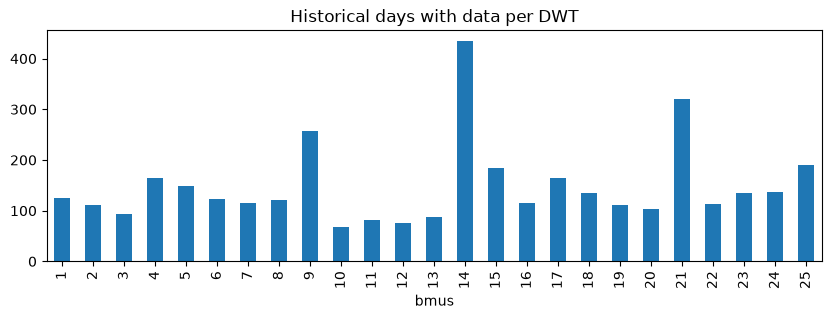

In [4]:
days_per_dwt = predictand["bmus"].value_counts().reindex(range(1, n_clusters + 1), fill_value=0)
days_per_dwt.plot(kind="bar", figsize=(10, 3), title="Historical days with data per DWT");

## Gaussian copula per DWT (precip + surge+setup + Q)

In [5]:
def simulate_dwt(dwt, n):
    """n random samples of (precip, ss, q) from the copula of a DWT."""
    obs = predictand.loc[predictand["bmus"] == dwt, var_names]
    sim = CopulaSimulation(
        U_data=obs.values.astype(float),
        kernels=[VARS[v][2] for v in var_names],
        num_sim=n,
    )
    for j, v in enumerate(var_names):
        if VARS[v][3]:
            sim[:, j] = np.clip(sim[:, j], 0, None)
    return sim


def simulate_series(dwt_series):
    """Simulate precip, ss and q for a DWT series of dimensions (time, n_sim)."""
    dwts = dwt_series.values
    out = {v: np.full(dwts.shape, np.nan) for v in var_names}
    for dwt in np.unique(dwts):
        mask = dwts == dwt
        sim = simulate_dwt(int(dwt), int(mask.sum()))
        for j, v in enumerate(var_names):
            out[v][mask] = sim[:, j]
    ds = xr.Dataset(
        {v: (dwt_series.dims, out[v]) for v in var_names},
        coords=dwt_series.coords,
    )
    ds["DWT"] = dwt_series
    for v in var_names:
        ds[v].attrs["label"] = VARS[v][1]
    return ds

### Copula correlation per DWT

Correlation in the normal space (Gaussian copula parameter) between each pair of variables, for each DWT.

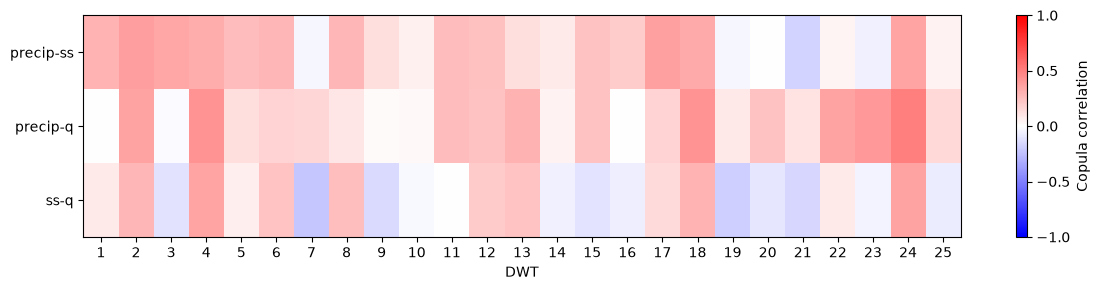

In [6]:
from scipy.special import ndtri
from statsmodels.distributions.empirical_distribution import ECDF

pairs = [("precip", "ss"), ("precip", "q"), ("ss", "q")]
rho = pd.DataFrame(index=pd.Index(range(1, n_clusters + 1), name="DWT"), columns=[f"{a}-{b}" for a, b in pairs], dtype=float)
for dwt in rho.index:
    obs = predictand.loc[predictand["bmus"] == dwt, var_names]
    z = pd.DataFrame({v: ndtri(np.clip(ECDF(obs[v])(obs[v]) * len(obs) / (len(obs) + 1), 1e-6, 1 - 1e-6)) for v in var_names})
    for a, b in pairs:
        rho.loc[dwt, f"{a}-{b}"] = z[a].corr(z[b])

fig, ax = plt.subplots(figsize=(12, 3))
im = ax.imshow(rho.T.values, cmap="bwr", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(n_clusters), rho.index)
ax.set_yticks(range(len(pairs)), rho.columns)
ax.set_xlabel("DWT")
fig.colorbar(im, ax=ax, label="Copula correlation")
plt.tight_layout()

## Climate emulator
### Simulated DWTs → precip, surge+setup and Q

The DWT series were simulated beforehand (100 years × 3 simulations, conditioned
on the simulated AWTs). Here we just sample the copulas day by day.

In [7]:
simulated_dwts = xr.open_dataset(DATA_DIR / "xds_output.nc")
n_sims = simulated_dwts.sizes["n_sim"]

simulated = simulate_series(simulated_dwts.evbmus_sims.transpose("time", "n_sim"))
simulated.to_netcdf(OUTPUT_DIR / "simulated_precip_ss_q.nc")
simulated

<xarray.Dataset> Size: 4MB
Dimensions:  (time: 36891, n_sim: 3)
Coordinates:
  * time     (time) datetime64[ns] 295kB 1999-01-01 1999-01-02 ... 2100-01-01
Dimensions without coordinates: n_sim
Data variables:
    precip   (time, n_sim) float64 885kB 0.7824 13.92 2.412 ... 12.18 1.748 0.0
    ss       (time, n_sim) float64 885kB -0.005598 0.07243 ... 0.352 0.03164
    q        (time, n_sim) float64 885kB 13.8 50.73 11.82 ... 85.7 0.0 58.37
    DWT      (time, n_sim) int64 885kB 20 20 20 20 23 20 20 ... 22 11 18 11 2 24

## Validation: observed vs simulated

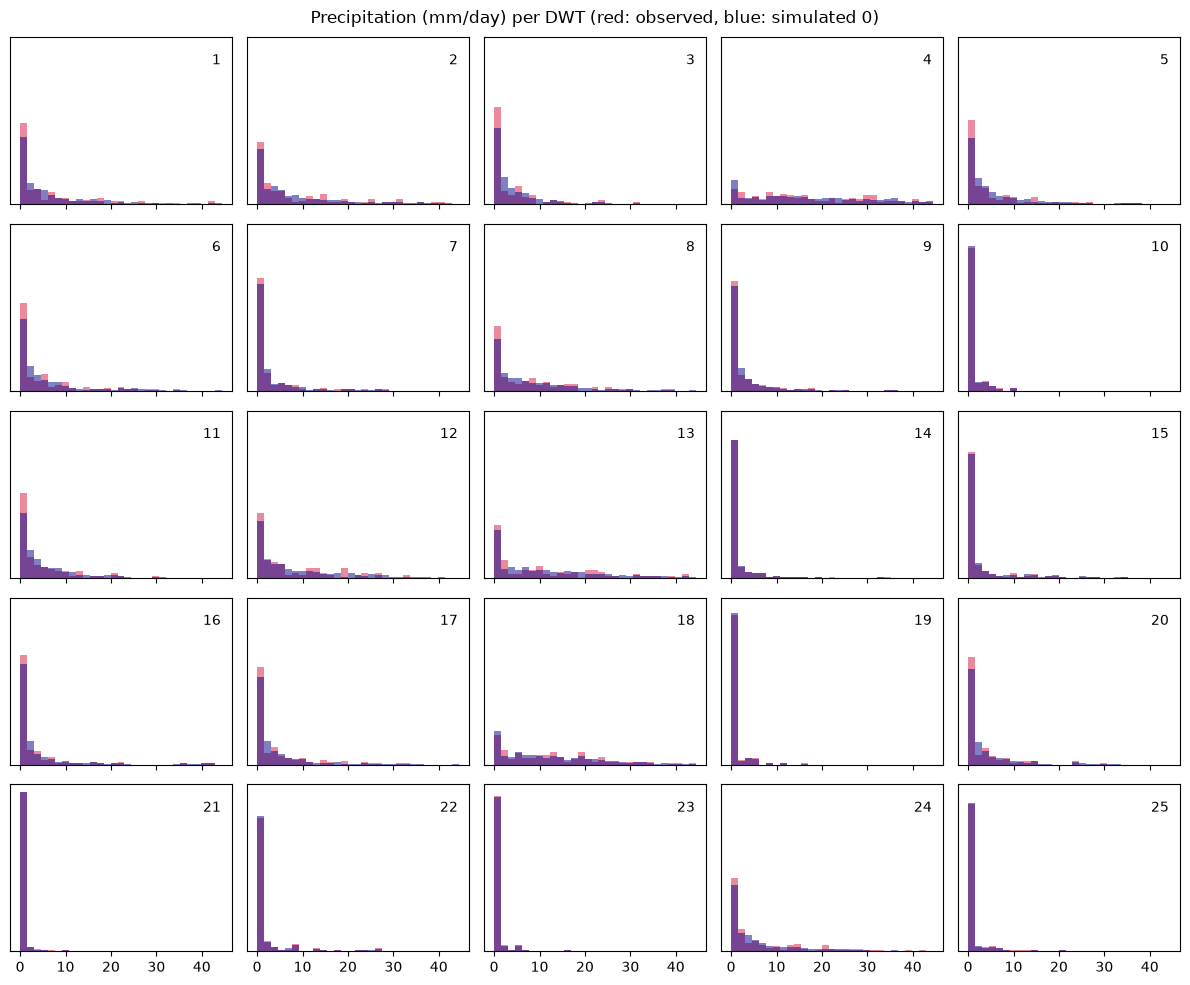

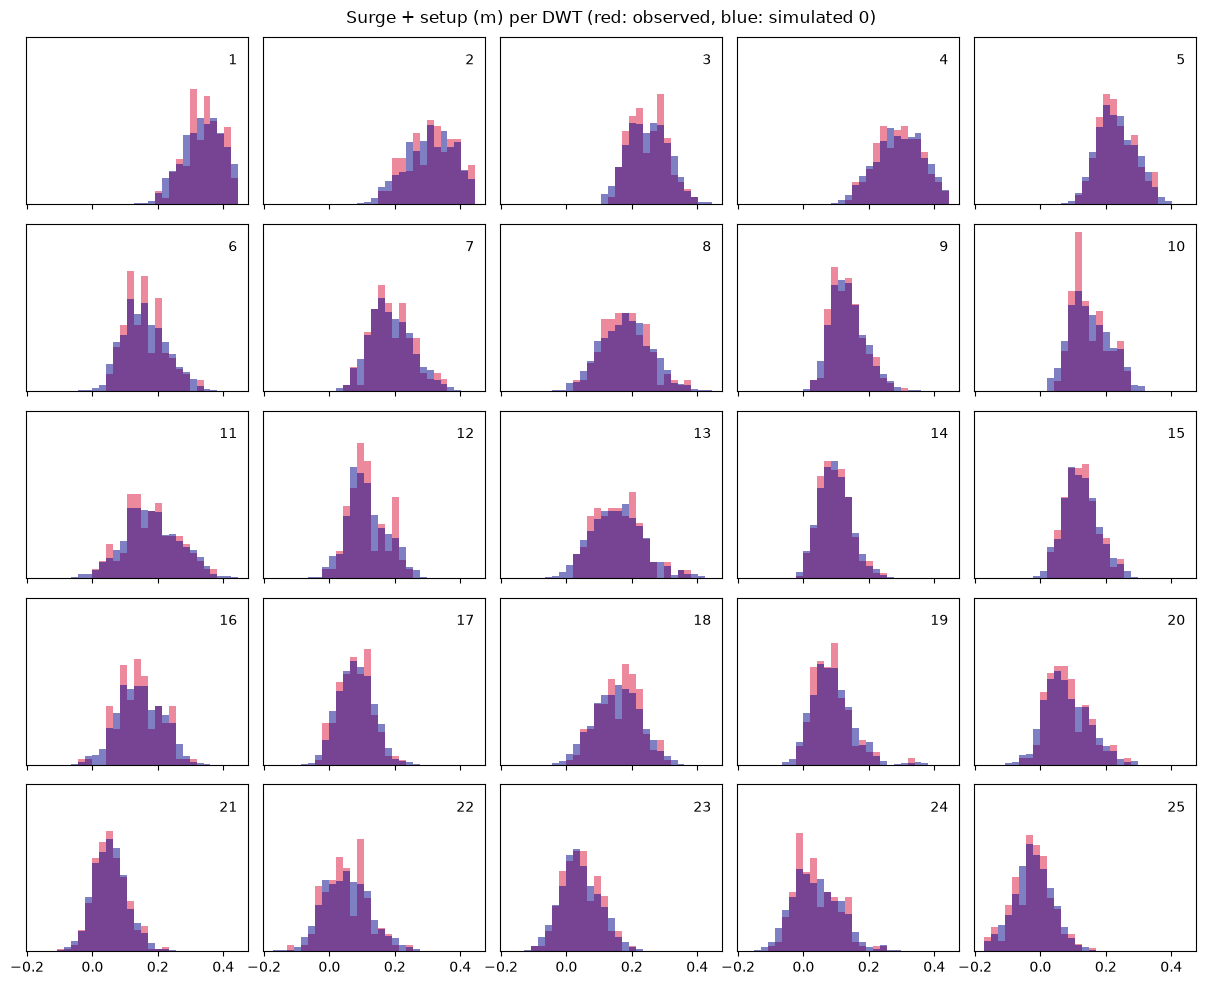

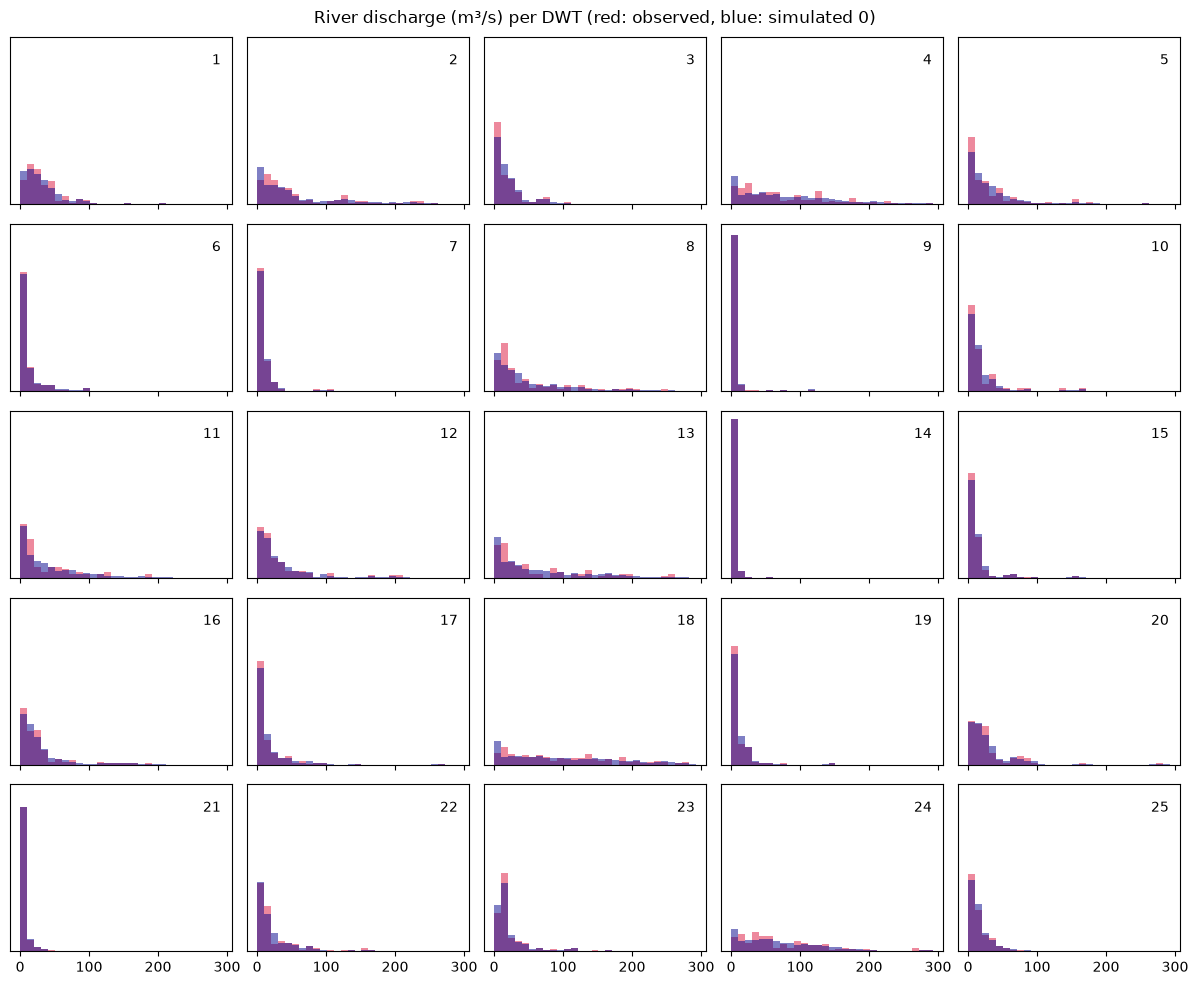

In [8]:
n_cols = int(np.ceil(np.sqrt(n_clusters)))
n_rows = int(np.ceil(n_clusters / n_cols))


def plot_hist_by_dwt(var, num_sim=0):
    sim = simulated.isel(n_sim=num_sim)
    upper = np.nanquantile(predictand[var], 0.99)
    bins = np.linspace(min(0, predictand[var].min()), upper, 30)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 10), sharex=True, sharey=True)
    for dwt, ax in zip(range(1, n_clusters + 1), axes.flatten()):
        ax.hist(predictand.loc[predictand["bmus"] == dwt, var], bins=bins, density=True, alpha=0.5, color="crimson")
        ax.hist(sim[var].where(sim.DWT == dwt, drop=True), bins=bins, density=True, alpha=0.5, color="darkblue")
        ax.text(0.95, 0.9, f"{dwt}", transform=ax.transAxes, ha="right", va="top")
        ax.set_yticks([])
    for ax in axes.flatten()[n_clusters:]:
        ax.set_visible(False)
    fig.suptitle(f"{VARS[var][1]} per DWT (red: observed, blue: simulated {num_sim})")
    plt.tight_layout()
    plt.show()


for var in var_names:
    plot_hist_by_dwt(var)

Spearman correlation - observed
        precip    ss     q
precip    1.00  0.40  0.36
ss        0.40  1.00  0.21
q         0.36  0.21  1.00

Spearman correlation - simulation 0
        precip    ss     q
precip    1.00  0.34  0.32
ss        0.34  1.00  0.16
q         0.32  0.16  1.00


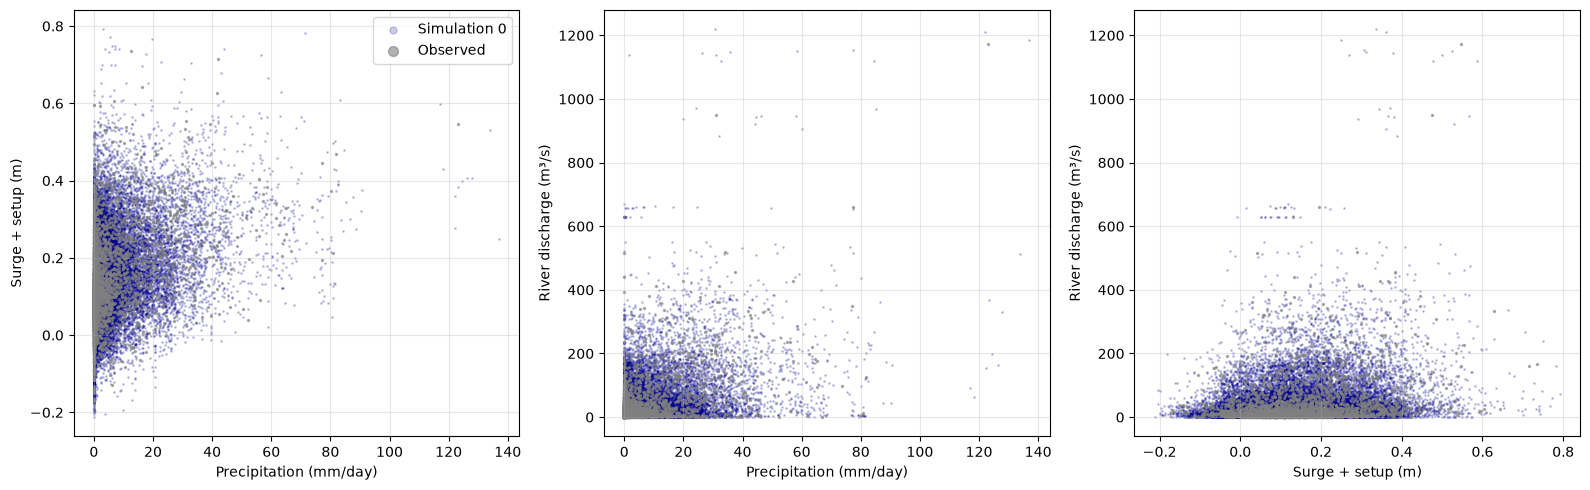

In [9]:
# Scatter of each pair of variables: observed (grey) vs one simulation (blue)
num_sim = 0
sim_df = simulated.isel(n_sim=num_sim)[var_names].to_dataframe()[var_names]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (a, b) in zip(axes, pairs):
    ax.scatter(sim_df[a], sim_df[b], s=1, color="darkblue", alpha=0.2, label=f"Simulation {num_sim}")
    ax.scatter(predictand[a], predictand[b], s=2, color="grey", alpha=0.6, label="Observed")
    ax.set_xlabel(VARS[a][1])
    ax.set_ylabel(VARS[b][1])
    ax.grid(alpha=0.3)
axes[0].legend(markerscale=5)
plt.tight_layout()

print("Spearman correlation - observed")
print(predictand[var_names].corr("spearman").round(2))
print(f"\nSpearman correlation - simulation {num_sim}")
print(sim_df.corr("spearman").round(2))

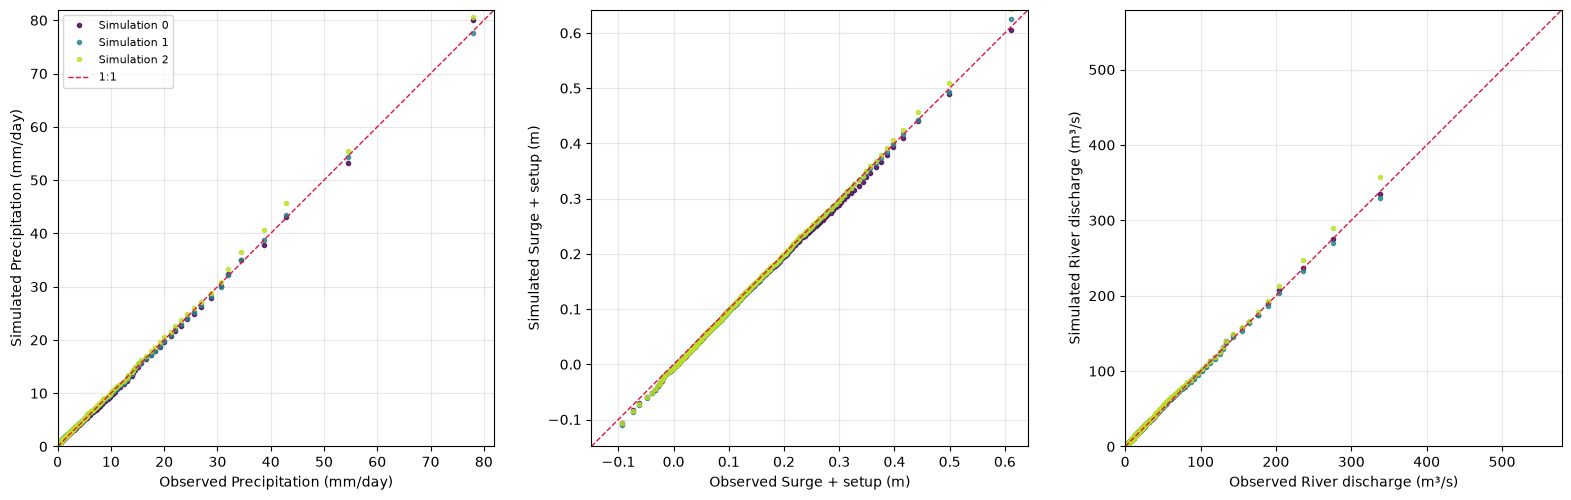

In [10]:
# QQ-plot of daily values: observed vs several simulations
probs = np.linspace(0.001, 0.999, 200)
colors = plt.cm.viridis(np.linspace(0, 0.9, n_sims))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, var in zip(axes, var_names):
    q_obs = np.nanquantile(predictand[var], probs)
    for i, color in enumerate(colors):
        q_sim = np.nanquantile(simulated[var].isel(n_sim=i), probs)
        ax.plot(q_obs, q_sim, "o", ms=3, color=color, alpha=0.8, label=f"Simulation {i}")
    lims = [min(0, q_obs.min()), 1.05 * q_obs.max()]
    ax.plot(lims, lims, "--", color="crimson", lw=1, label="1:1")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect("equal")
    ax.set_xlabel(f"Observed {VARS[var][1]}")
    ax.set_ylabel(f"Simulated {VARS[var][1]}")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()

## Extremes
### Annual maxima: historical vs simulations

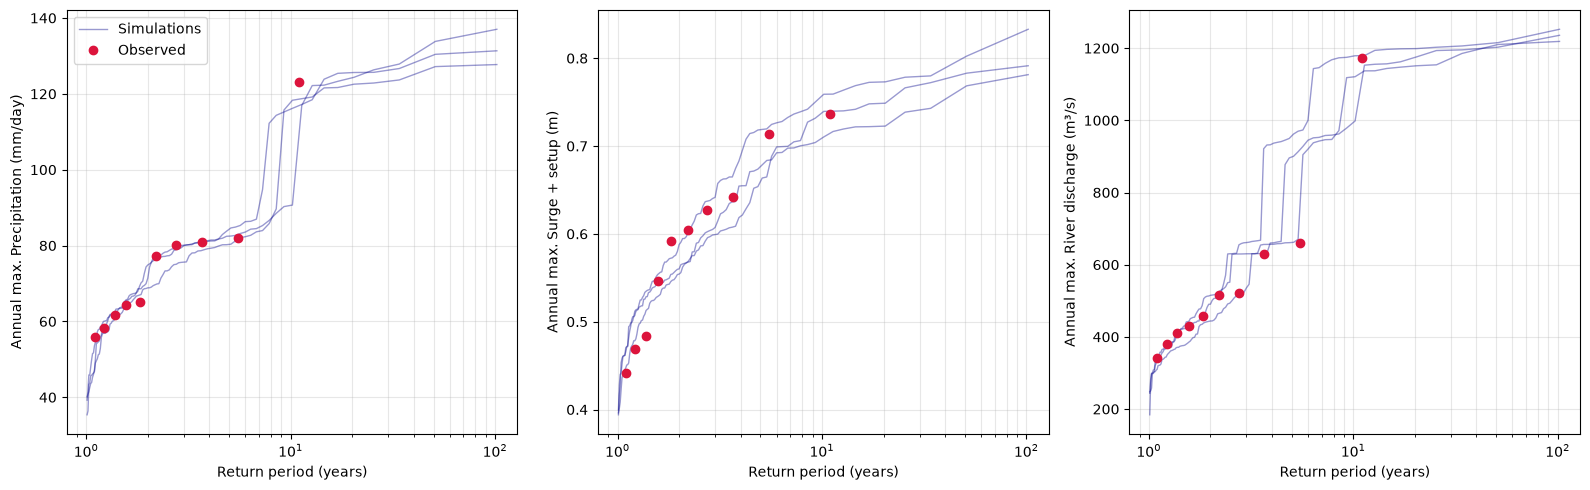

In [11]:
def return_period_plot(ax, annual_max, **kw):
    x = np.sort(annual_max)
    tr = (len(x) + 1) / (len(x) + 1 - np.arange(1, len(x) + 1))
    ax.semilogx(tr, x, **kw)


fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, var in zip(axes, var_names):
    for i in range(n_sims):
        sim_i = simulated[var].isel(n_sim=i).to_series()
        am_sim = sim_i.resample("YS").max()[sim_i.resample("YS").count() > 300].values  # complete years only
        return_period_plot(ax, am_sim, color="darkblue", alpha=0.4, lw=1, label="Simulations" if i == 0 else None)
    am_obs = predictand[var].resample("YS").max()
    am_obs = am_obs[predictand[var].resample("YS").count() > 300]  # complete years only
    return_period_plot(ax, am_obs.values, color="crimson", marker="o", ls="none", label="Observed")
    ax.set_xlabel("Return period (years)")
    ax.set_ylabel(f"Annual max. {VARS[var][1]}")
    ax.grid(alpha=0.3, which="both")
axes[0].legend()
plt.tight_layout()

### Time series of one simulation: precip, surge+setup, Q, DWT and AWT

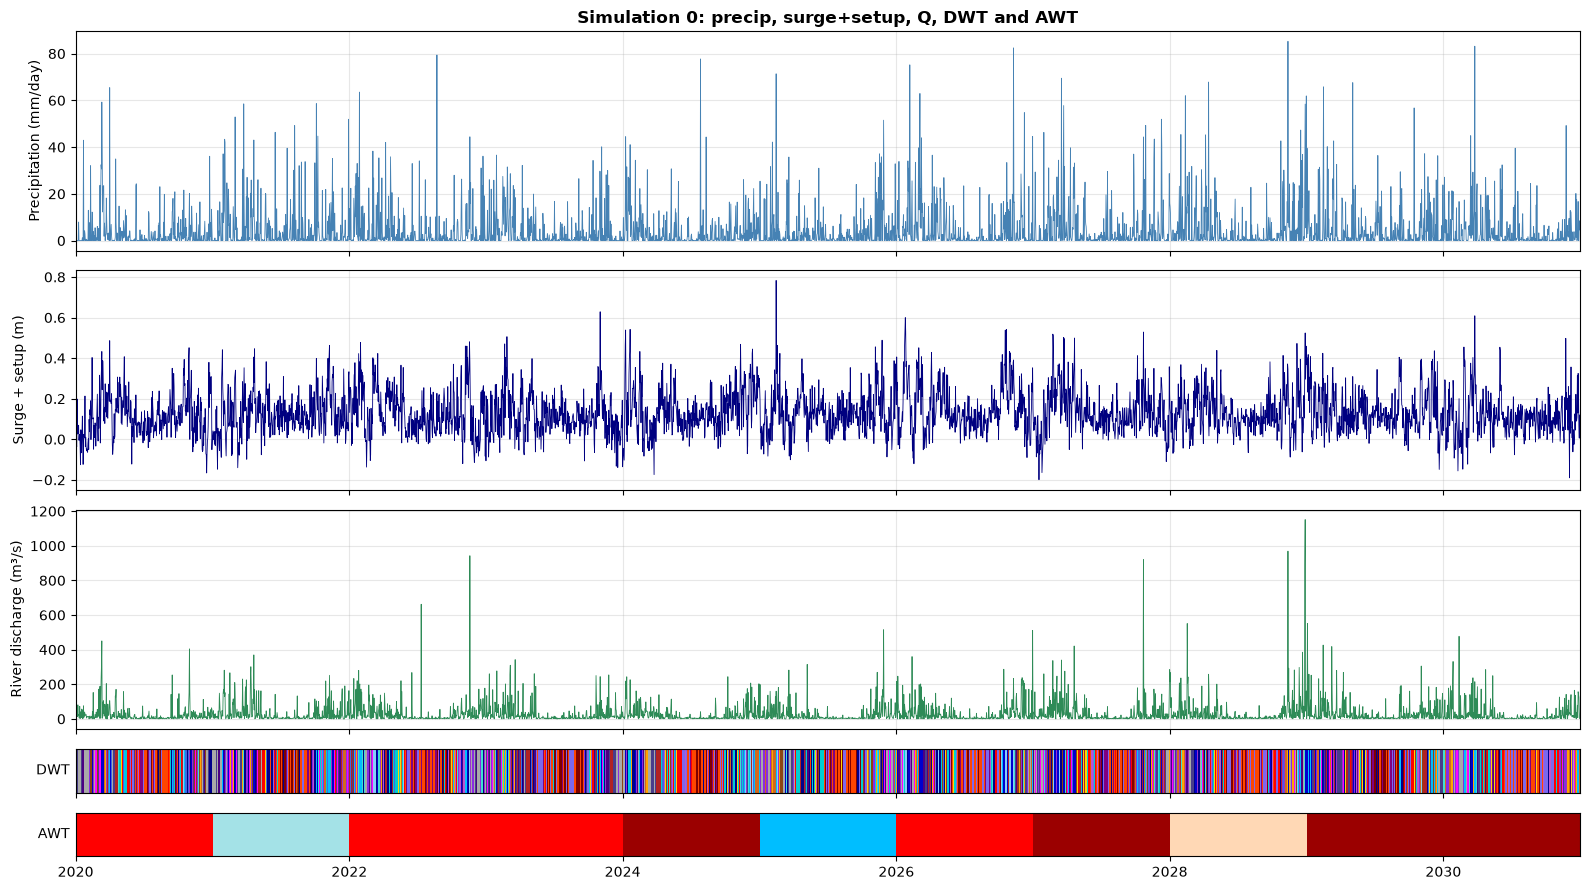

In [12]:
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap, BoundaryNorm
from bluemath_tk.teslakit.plotting.custom_colors import colors_awt

num_sim = 0                       # simulation to plot (max. n_sims - 1)
t_ini, t_end = "2020", "2030"     # period to plot (None = whole series)
series_colors = {"precip": "steelblue", "ss": "navy", "q": "seagreen"}

# Simulated AWTs (annual). The DWT simulation n was driven by the AWT simulation n
awt_sims = xr.open_dataset(DATA_DIR / "AWT_SIM_nsims3_2000_2100.nc")

sim = simulated.isel(n_sim=num_sim).sel(time=slice(t_ini, t_end))
dwt = sim.DWT
awt = awt_sims.evbmus_sims.isel(n_sim=num_sim).reindex(time=dwt.time, method="pad")

n_awt = int(awt_sims.evbmus_sims.max())
bands = [
    ("DWT", dwt, np.asarray(get_cluster_colors(n_clusters), dtype=float)[:, :3]),
    ("AWT", awt, colors_awt()[:n_awt]),
]

fig, axes = plt.subplots(
    len(var_names) + len(bands), 1, figsize=(16, 9), sharex=True,
    gridspec_kw={"height_ratios": [3] * len(var_names) + [0.6] * len(bands)},
)
for ax, var in zip(axes, var_names):
    ax.plot(sim.time, sim[var], color=series_colors[var], lw=0.6)
    ax.set_ylabel(VARS[var][1])
    ax.grid(alpha=0.3)

edges = mdates.date2num(np.r_[dwt.time.values, dwt.time.values[-1] + np.timedelta64(1, "D")])
for ax, (name, series, colors) in zip(axes[len(var_names):], bands):
    ax.set_yticks([])
    ax.set_ylabel(name, rotation=0, ha="right", va="center")
    k = len(colors)
    ax.pcolormesh(edges, [0, 1], series.values[None, :],
                  cmap=ListedColormap(colors), norm=BoundaryNorm(np.arange(0.5, k + 1.5), k))

axes[-1].xaxis_date()
axes[-1].set_xlim(edges[0], edges[-1])
axes[0].set_title(f"Simulation {num_sim}: precip, surge+setup, Q, DWT and AWT", fontweight="bold")
plt.tight_layout()
plt.show()

## Summary

We have 3 × 100 years of daily precipitation, surge + setup and river
discharge, with the right dependence between them for each weather type. In
`04_Flood_climate.ipynb` we add the tide, run all these days through the
surrogate and obtain the flood statistics of the estuary.